# Understand `grids` Module

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://drive.google.com/file/d/1UscrnK5wWiT-ad_9GSsxBwBuHuUuCVCO/view?usp=drive_link&target=_blank)

*Author: Zakariya Abugrin | Date: May 2025*

In [1]:
# Colab only:
try:
    # Install reservoirflow in Colab
    import os
    import google.colab
    !pip install -q reservoirflow
    # Restart session after installation
    os.kill(os.getpid(), 9)
    print("Session was restarted.")
    print("Now you can run to the following cells.")
except ImportError:
    pass

## Introduction

In this tutorial, we will see how the `grids` module is an essential part of any model in `reservoirflow` which allows to create a grid model. Currently, only `RegularCartesianGrid` grid models are supported. In the near future, `Radial` and `IrregularCartesian` models will be added.

In [2]:
import reservoirflow as rf

print(rf.__version__)

0.1.0b3


## Create 1D Model

We can use `RegularCartesianGrid` from `grids` module to build a gird, see the [documentation](/api/reservoirflow.grids.html#reservoirflow.grids.RegularCartesianGrid).

Grid model dimensionality can be defined based on `nx, ny, nz` arguments as following:

In [3]:
# Create a 1D regular cartesian grid:
grid = rf.grids.RegularCartesianGrid(
    nx=4,
    ny=1,
    nz=1,
    dx=200,
    dy=200,
    dz=40,
    phi=0.27,
    kx=270,
    ky=200,
    kz=10,
    comp=1e-6,
    unit="field",
)

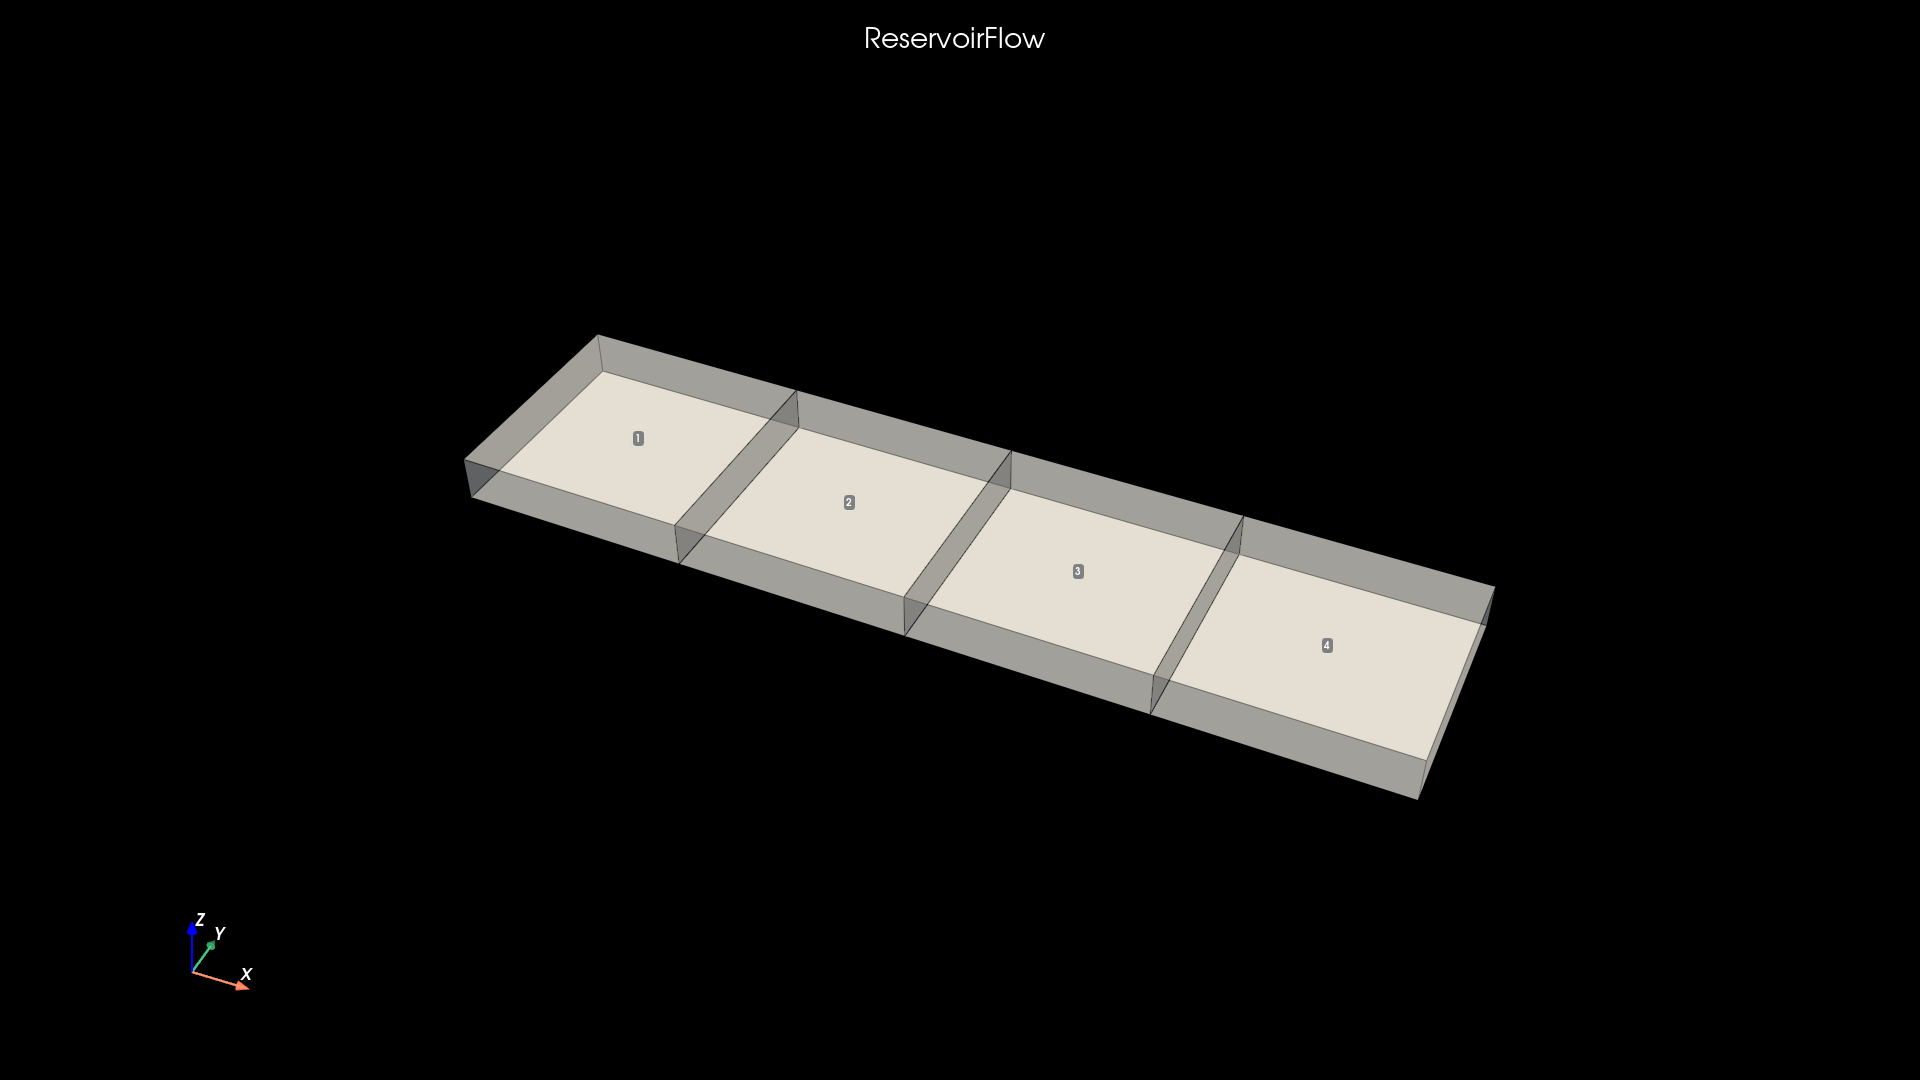

In [4]:
# Show the grid model with cells id
a = grid.show(
    label="id",
    boundary=False,
    static=True,
    notebook=True,
    azimuth=25,
)

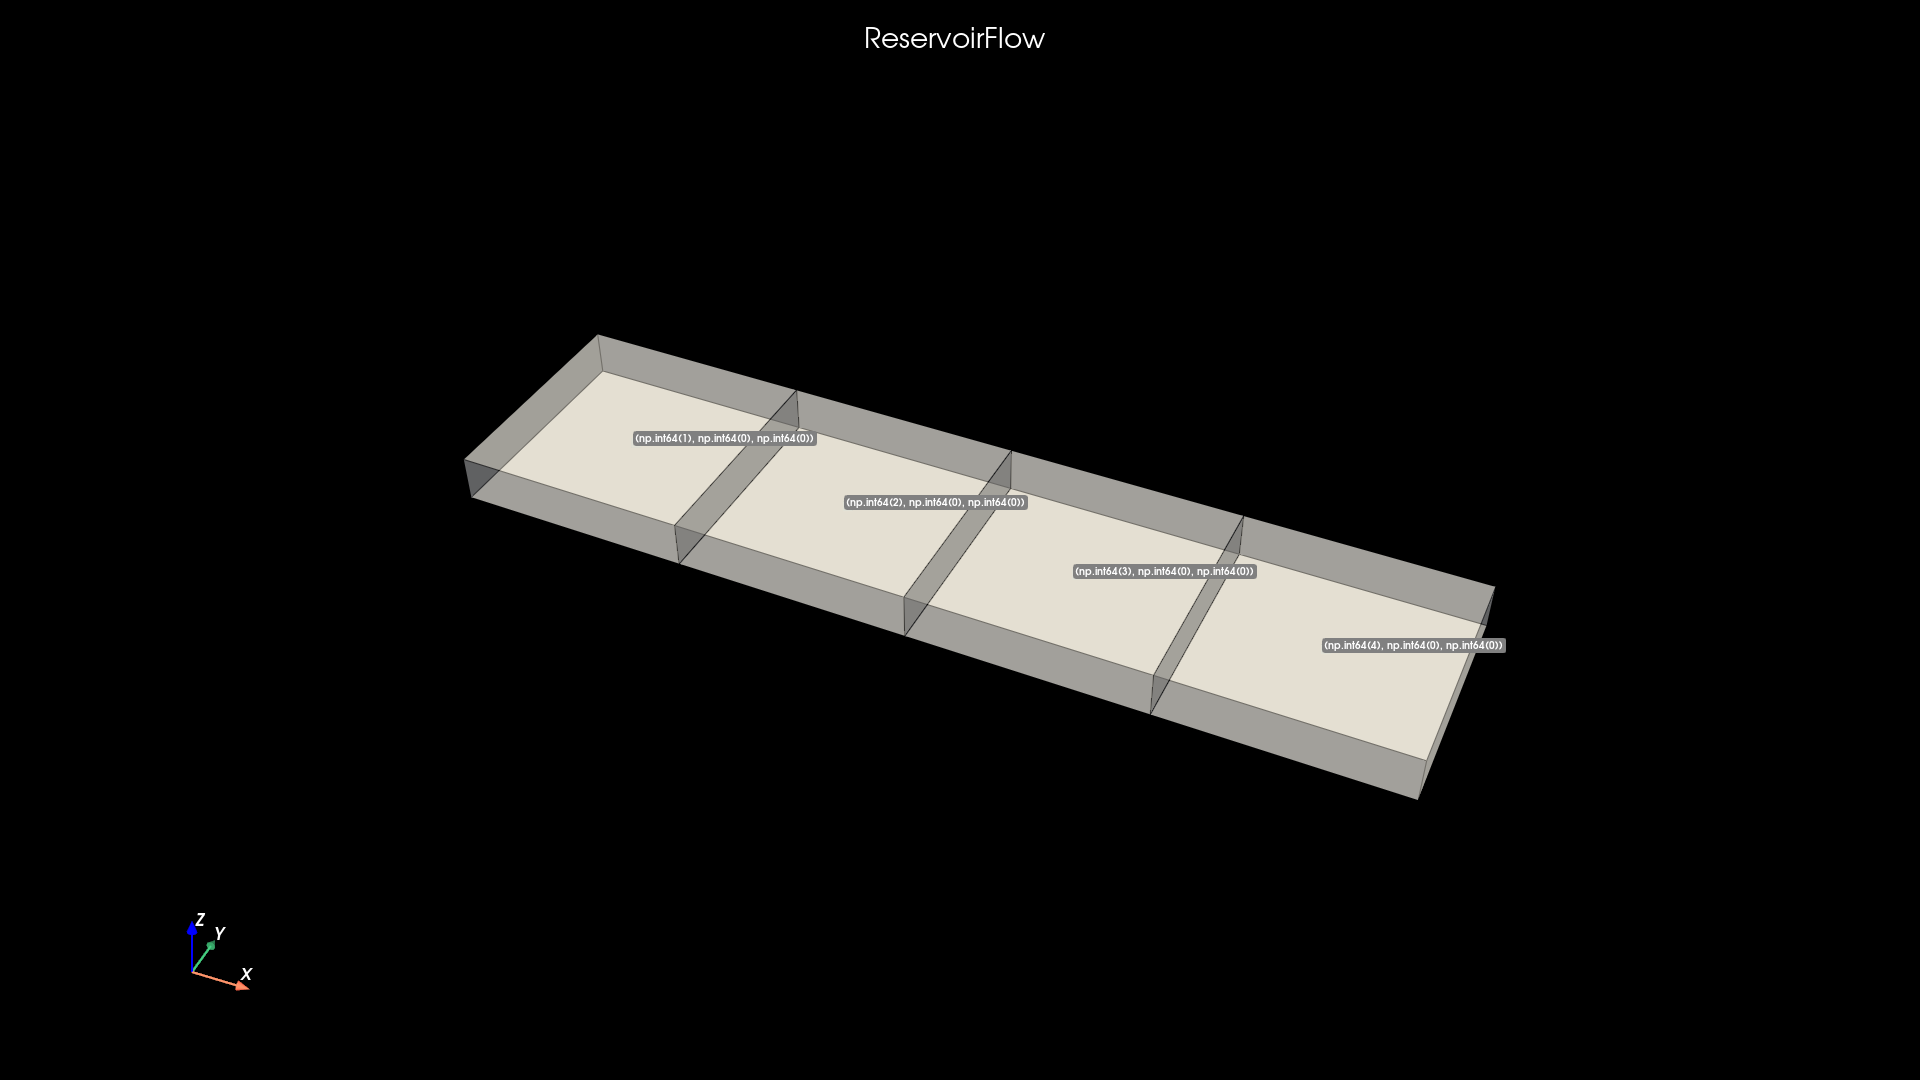

In [5]:
# Show the grid model with cells id
grid.show(
    label="coords",
    boundary=False,
    static=True,
    notebook=True,
    azimuth=25,
)

## Cells id

Cells id are arranged in natural order starting from the bottom left corner and can be accessed in several ways:

- attribute `cells_id` provides cells_id without boundary cells as flat array:

In [6]:
grid.cells_id

array([1, 2, 3, 4])

- more options can be found under `get_cells_id()` method:

In [7]:
cells_id = grid.get_cells_id(boundary=False, fshape=True, fmt="array")
cells_id.shape  # -> (nz, ny, nx)

(1, 1, 4)

Note: `fshape` (flow shape) argument provides the `cells_id` array as flow shape (nz, ny, nx) and `boundary` argument can be used to include or exclude boundary cells.

Using `nz=3`, but actually `nz=5` (i.e. 5 layers) in total including upper and lower boundaries. If you do not want to deal with boundary cells just set `boundary=False`.

```{include} /_static/comments_section.md
```